# drone collision prevention - closest pair

DSA assignment. drones are points in 2D/3D and we want the closest pair(s) fast, then keep tracking them while drones move.

seed is fixed so the datasets and movements are the same every run.

In [18]:
import csv
import random
import time
import math
import heapq
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple, Iterable, Optional
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

## 1. datasets

random drone positions in a square (2D) or cube (3D), saved as csv so i don't regenerate every time. sizes go from 1k up to 10M.

generating the big ones takes a while, so `GENERATE_FILES` is a switch.

In [6]:
MAP_SIZE = 10_000  # coordinate range is [0, MAP_SIZE]
DATA_DIR = Path("datasets")
DATA_DIR.mkdir(exist_ok=True)

def generate_csv(path: Path, n: int, dim: int) -> None:
    if dim not in (2, 3):
        raise ValueError("dim must be 2 or 3")

    headers = ["id", "x", "y"] if dim == 2 else ["id", "x", "y", "z"]

    with path.open("w", newline="") as f:
        w = csv.writer(f)
        w.writerow(headers)
        for i in range(n):
            coords = [random.uniform(0.0, MAP_SIZE) for _ in range(dim)]
            w.writerow([i] + coords)

def maybe_generate_all(sizes: List[int], generate_files: bool = False) -> None:
    if not generate_files:
        return

    for n in sizes:
        generate_csv(DATA_DIR / f"data_2d_{n}.csv", n, 2)
        generate_csv(DATA_DIR / f"data_3d_{n}.csv", n, 3)

SIZES = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
GENERATE_FILES = True # I changed to False after generating the files
maybe_generate_all(SIZES, generate_files=GENERATE_FILES)

def load_2d(path: Path) -> List[Tuple[int, float, float]]:
    pts: List[Tuple[int, float, float]] = []
    with path.open("r", newline="") as f:
        r = csv.DictReader(f)
        for row in r:
            pts.append((int(row["id"]), float(row["x"]), float(row["y"])))
    return pts

def load_3d(path: Path) -> List[Tuple[int, float, float, float]]:
    pts: List[Tuple[int, float, float, float]] = []
    with path.open("r", newline="") as f:
        r = csv.DictReader(f)
        for row in r:
            pts.append((int(row["id"]), float(row["x"]), float(row["y"]), float(row["z"])))
    return pts


## 2. distance helpers

using squared distance everywhere (no sqrt in the loops), it doesn't change which pair is closest. sqrt only when printing.

ties: if two pairs have the same distance, pick the smaller (id1, id2). same rule in every method so outputs match.

In [7]:
def dist2_2d(a: Tuple[int, float, float], b: Tuple[int, float, float]) -> float:
    dx = a[1] - b[1]
    dy = a[2] - b[2]
    return dx*dx + dy*dy

def dist2_3d(a: Tuple[int, float, float, float], b: Tuple[int, float, float, float, float]) -> float:
    dx = a[1] - b[1]
    dy = a[2] - b[2]
    dz = a[3] - b[3]
    return dx*dx + dy*dy + dz*dz

def ordered_pair(a_id: int, b_id: int) -> Tuple[int, int]:
    return (a_id, b_id) if a_id <= b_id else (b_id, a_id)

def better_pair_tiebreak(p: Tuple[int,int], q: Tuple[int,int]) -> bool:
    return p < q


## 3. task 1 (2D) - brute force

check every pair. Θ(n²) time, O(1) extra space. used as the baseline and to check the fast version.

In [8]:
def closest_pair_bruteforce_2d(points: List[Tuple[int, float, float]]) -> Tuple[float, Tuple[int,int]]:
    best_d2 = float("inf")
    best_pair = (10**18, 10**18)

    n = len(points)
    for i in range(n):
        for j in range(i + 1, n):
            d2 = dist2_2d(points[i], points[j])
            pair = ordered_pair(points[i][0], points[j][0])
            if (d2 < best_d2) or (d2 == best_d2 and better_pair_tiebreak(pair, best_pair)):
                best_d2 = d2
                best_pair = pair

    return best_d2, best_pair

def run_baseline_2d(path: Path) -> Tuple[float, Tuple[int,int], float]:
    points = load_2d(path)
    t0 = time.time()
    best_d2, best_pair = closest_pair_bruteforce_2d(points)
    t1 = time.time()
    return best_d2, best_pair, (t1 - t0)


## 4. task 1 (2D) - divide & conquer

the classic one:
1. sort by x and by y once
2. split at the median x and recurse on both halves
3. δ = best of the two halves
4. strip = points closer than δ to the split line
5. go through the strip in y order, each point only needs to be compared with the next 7

a crossing pair closer than δ has to be in the strip, and the packing argument limits the comparisons per point to a constant. O(n log n) worst case, O(n) space.

In [9]:
def _closest_pair_dc_2d(px: List[Tuple[int,float,float]],
                        py: List[Tuple[int,float,float]]) -> Tuple[float, Tuple[int,int]]:
    n = len(px)
    if n <= 3:
        return closest_pair_bruteforce_2d(px)

    mid = n // 2
    left_x = px[:mid]
    right_x = px[mid:]
    mid_x = px[mid][1]

    left_ids = {p[0] for p in left_x}
    left_y = [p for p in py if p[0] in left_ids]
    right_y = [p for p in py if p[0] not in left_ids]

    d2_left, pair_left = _closest_pair_dc_2d(left_x, left_y)
    d2_right, pair_right = _closest_pair_dc_2d(right_x, right_y)

    # choose best from halves (with tie-break)
    if (d2_left < d2_right) or (d2_left == d2_right and better_pair_tiebreak(pair_left, pair_right)):
        best_d2, best_pair = d2_left, pair_left
    else:
        best_d2, best_pair = d2_right, pair_right

    # strip: points within sqrt(best_d2) in x => dx^2 < best_d2
    strip = [p for p in py if (p[1] - mid_x) ** 2 < best_d2]

    # check up to next 7 points in y-order
    for i in range(len(strip)):
        for j in range(i + 1, min(i + 8, len(strip))):
            d2 = dist2_2d(strip[i], strip[j])
            pair = ordered_pair(strip[i][0], strip[j][0])
            if (d2 < best_d2) or (d2 == best_d2 and better_pair_tiebreak(pair, best_pair)):
                best_d2, best_pair = d2, pair

    return best_d2, best_pair

def closest_pair_dc_2d(points: List[Tuple[int,float,float]]) -> Tuple[float, Tuple[int,int]]:
    px = sorted(points, key=lambda p: p[1])
    py = sorted(points, key=lambda p: p[2])
    return _closest_pair_dc_2d(px, py)

def run_improved_2d(path: Path) -> Tuple[float, Tuple[int,int], float]:
    points = load_2d(path)
    t0 = time.time()
    best_d2, best_pair = closest_pair_dc_2d(points)
    t1 = time.time()
    return best_d2, best_pair, (t1 - t0)


## 5. task 2 (3D) - brute force

same as task 1 but with z. Θ(n²), so for big n it's skipped.

In [10]:
def closest_pair_bruteforce_3d(points: List[Tuple[int,float,float,float]]) -> Tuple[float, Tuple[int,int]]:
    best_d2 = float("inf")
    best_pair = (10**18, 10**18)

    n = len(points)
    for i in range(n):
        for j in range(i + 1, n):
            d2 = dist2_3d(points[i], points[j])
            pair = ordered_pair(points[i][0], points[j][0])
            if (d2 < best_d2) or (d2 == best_d2 and better_pair_tiebreak(pair, best_pair)):
                best_d2, best_pair = d2, pair

    return best_d2, best_pair

def run_baseline_3d(path: Path) -> Tuple[float, Tuple[int,int], float]:
    points = load_3d(path)
    t0 = time.time()
    best_d2, best_pair = closest_pair_bruteforce_3d(points)
    t1 = time.time()
    return best_d2, best_pair, (t1 - t0)


## 6. task 2 (3D) - divide & conquer + grid in the slab

split by x like in 2D. the hard part is the slab, in 3D you can't just check "next 7 points". so i put the slab points in a hash grid on (y, z) with cell size δ and only check the 9 neighbouring cells.

worst case is still Θ(n²) if everything is clustered in one cell, but for spread out points it's close to O(n log n) in practice.

In [11]:
def _cell_index(val: float, w: float) -> int:
    return int(val // w)

def _closest_pair_dc_3d(px: List[Tuple[int,float,float,float]]) -> Tuple[float, Tuple[int,int]]:
    n = len(px)
    if n <= 40:  # small cases: brute force is faster in python
        return closest_pair_bruteforce_3d(px)

    mid = n // 2
    left = px[:mid]
    right = px[mid:]
    mid_x = px[mid][1]

    d2_left, pair_left = _closest_pair_dc_3d(left)
    d2_right, pair_right = _closest_pair_dc_3d(right)

    if (d2_left < d2_right) or (d2_left == d2_right and better_pair_tiebreak(pair_left, pair_right)):
        best_d2, best_pair = d2_left, pair_left
    else:
        best_d2, best_pair = d2_right, pair_right

    # slab: dx^2 < best_d2
    slab = [p for p in px if (p[1] - mid_x) ** 2 < best_d2]

    # spatial hash on (y,z)
    if best_d2 == 0.0:
        return best_d2, best_pair

    w = math.sqrt(best_d2)
    grid: Dict[Tuple[int,int], List[Tuple[int,float,float,float]]] = {}

    # process slab points in x order is fine
    for p in slab:
        cy = _cell_index(p[2], w)
        cz = _cell_index(p[3], w)

        # check 9 neighbor cells in yz-plane (cy±1, cz±1)
        for dy in (-1, 0, 1):
            for dz in (-1, 0, 1):
                for q in grid.get((cy + dy, cz + dz), []):
                    d2 = dist2_3d(p, q)
                    pair = ordered_pair(p[0], q[0])
                    if (d2 < best_d2) or (d2 == best_d2 and better_pair_tiebreak(pair, best_pair)):
                        best_d2, best_pair = d2, pair
                        w = math.sqrt(best_d2) if best_d2 > 0 else w  # shrink window if improved

        grid.setdefault((cy, cz), []).append(p)

    return best_d2, best_pair

def closest_pair_dc_3d(points: List[Tuple[int,float,float,float]]) -> Tuple[float, Tuple[int,int]]:
    px = sorted(points, key=lambda p: p[1])
    return _closest_pair_dc_3d(px)

def run_improved_3d(path: Path) -> Tuple[float, Tuple[int,int], float]:
    points = load_3d(path)
    t0 = time.time()
    best_d2, best_pair = closest_pair_dc_3d(points)
    t1 = time.time()
    return best_d2, best_pair, (t1 - t0)


## 7. task 3 (3D) - top-k brute force

compute all pairs, sort, take the first k. Θ(n² log n) time and Θ(n²) memory, only works for small n.

In [12]:
def topk_baseline_3d(points: List[Tuple[int,float,float,float]], k: int) -> List[Tuple[float, Tuple[int,int]]]:
    pairs: List[Tuple[float, Tuple[int,int]]] = []
    n = len(points)
    for i in range(n):
        for j in range(i + 1, n):
            d2 = dist2_3d(points[i], points[j])
            pair = ordered_pair(points[i][0], points[j][0])
            pairs.append((d2, pair))

    pairs.sort(key=lambda x: (x[0], x[1][0], x[1][1]))
    return pairs[:k]

def run_topk_baseline_3d(path: Path, k: int) -> Tuple[List[Tuple[float, Tuple[int,int]]], float]:
    points = load_3d(path)
    t0 = time.time()
    res = topk_baseline_3d(points, k)
    t1 = time.time()
    return res, (t1 - t0)


## 8. task 3 (3D) - top-k with sweep + max-heap

- sort by x
- for each point, go back over earlier points while the x gap is still small enough
- keep a max-heap of size k with the best pairs so far, its top is the current k-th distance δ

if dx² > δ the real distance is also > δ, and since points are sorted by x every earlier point is even further, so we can break.

worst case O(n² log k) (lots of points with similar x), but normally way faster than the baseline. ids are in the heap items so ties are deterministic.

In [13]:
def _heap_item(d2: float, pair: Tuple[int,int]) -> Tuple[float, int, int]:
    # max-heap via negative distance, and negative IDs to keep deterministic order for equal distances
    return (-d2, -pair[0], -pair[1])

def topk_sweep_3d(points: List[Tuple[int,float,float,float]], k: int) -> List[Tuple[float, Tuple[int,int]]]:
    pts = sorted(points, key=lambda p: p[1])  # by x
    heap: List[Tuple[float,int,int]] = []     # stores (-d2, -id1, -id2)

    def current_threshold() -> float:
        return float("inf") if len(heap) < k else -heap[0][0]

    for i in range(len(pts)):
        d2_thr = current_threshold()
        j = i - 1
        while j >= 0:
            dx = pts[i][1] - pts[j][1]
            if dx*dx > d2_thr:
                break
            d2 = dist2_3d(pts[i], pts[j])
            pair = ordered_pair(pts[i][0], pts[j][0])
            item = _heap_item(d2, pair)

            if len(heap) < k:
                heapq.heappush(heap, item)
            else:
                if item > heap[0]:  # better than current worst
                    heapq.heapreplace(heap, item)

            d2_thr = current_threshold()
            j -= 1

    # convert to sorted (d2, pair)
    res = [(-neg_d2, (-neg_id1, -neg_id2)) for (neg_d2, neg_id1, neg_id2) in heap]
    res.sort(key=lambda x: (x[0], x[1][0], x[1][1]))
    return res

def run_topk_improved_3d(path: Path, k: int) -> Tuple[List[Tuple[float, Tuple[int,int]]], float]:
    points = load_3d(path)
    t0 = time.time()
    res = topk_sweep_3d(points, k)
    t1 = time.time()
    return res, (t1 - t0)


## 9. benchmarks

timing baseline vs optimized for tasks 1-3 across sizes (and different k for task 3). only the algorithm is timed, not file loading. baselines are skipped for sizes where they'd take forever.

,n,baseline_s,optimized_s
0,1000,0.105352,0.004236
1,10000,9.280462,0.061807
2,100000,1588.264842,0.845222
3,1000000,NaN,12.330943
4,10000000,NaN,163.261643


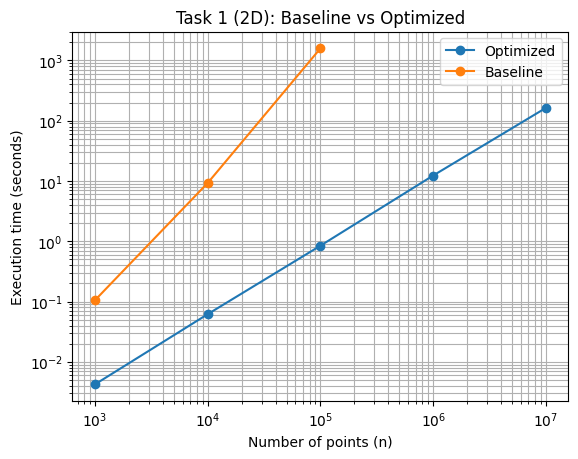

,n,baseline_s,optimized_s
0,1000,0.131103,0.005571
1,10000,11.797069,0.077051
2,100000,1177.068652,0.890065
3,1000000,NaN,12.111825
4,10000000,NaN,230.792508


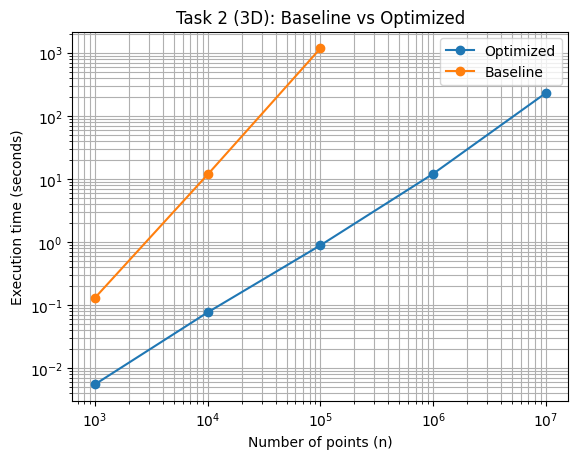

,n,k,baseline_s,optimized_s
0,1000,1,0.407862,0.005979
1,1000,5,0.413607,0.009897
2,1000,10,0.414206,0.011392
3,1000,50,0.402281,0.019650
4,10000,1,73.902813,0.107410
5,10000,5,78.128969,0.208313
6,10000,10,76.009529,0.260878
7,10000,50,78.738384,0.440313
8,100000,1,NaN,1.883730
9,100000,5,NaN,3.746439


In [19]:
def benchmark_task1_2d(sizes: List[int]) -> pd.DataFrame:
    rows = []
    for n in sizes:
        path = DATA_DIR / f"data_2d_{n}.csv"
        if not path.exists():
            continue

        # Baseline only for feasible sizes
        t_base = None
        if n <= 100_000:
            _, _, t_base = run_baseline_2d(path)

        _, _, t_opt = run_improved_2d(path)
        rows.append({"n": n, "baseline_s": t_base, "optimized_s": t_opt})
    return pd.DataFrame(rows)

def benchmark_task2_3d(sizes: List[int]) -> pd.DataFrame:
    rows = []
    for n in sizes:
        path = DATA_DIR / f"data_3d_{n}.csv"
        if not path.exists():
            continue

        t_base = None
        if n <= 100_000:
            _, _, t_base = run_baseline_3d(path)

        _, _, t_opt = run_improved_3d(path)
        rows.append({"n": n, "baseline_s": t_base, "optimized_s": t_opt})
    return pd.DataFrame(rows)

def benchmark_task3_topk(sizes: List[int], k_values: List[int]) -> pd.DataFrame:
    rows = []
    for n in sizes:
        path = DATA_DIR / f"data_3d_{n}.csv"
        if not path.exists():
            continue

        for k in k_values:
            # Baseline only for small n
            t_base = None
            if n <= 10_000:
                _, t_base = run_topk_baseline_3d(path, k)

            _, t_opt = run_topk_improved_3d(path, k)
            rows.append({"n": n, "k": k, "baseline_s": t_base, "optimized_s": t_opt})
    return pd.DataFrame(rows)

def plot_baseline_vs_opt(df: pd.DataFrame, title: str) -> None:
    plt.figure()
    x = df["n"].tolist()
    y_opt = df["optimized_s"].tolist()
    plt.loglog(x, y_opt, marker="o", label="Optimized")
    if df["baseline_s"].notna().any():
        df2 = df.dropna(subset=["baseline_s"])
        plt.loglog(df2["n"].tolist(), df2["baseline_s"].tolist(), marker="o", label="Baseline")
    plt.xlabel("Number of points (n)")
    plt.ylabel("Execution time (seconds)")
    plt.title(title)
    plt.legend()
    plt.grid(True, which="both")
    plt.show()

df1 = benchmark_task1_2d(SIZES)
display(df1)
plot_baseline_vs_opt(df1, "Task 1 (2D): Baseline vs Optimized")

df2 = benchmark_task2_3d(SIZES)
display(df2)
plot_baseline_vs_opt(df2, "Task 2 (3D): Baseline vs Optimized")

df3 = benchmark_task3_topk([1_000, 10_000, 100_000, 1_000_000], [1, 5, 10, 50])
display(df3)


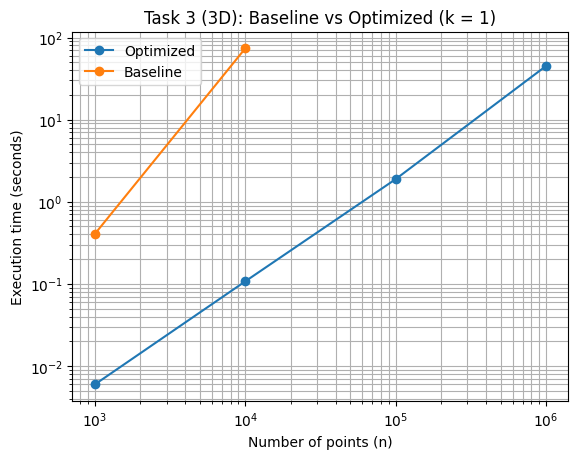

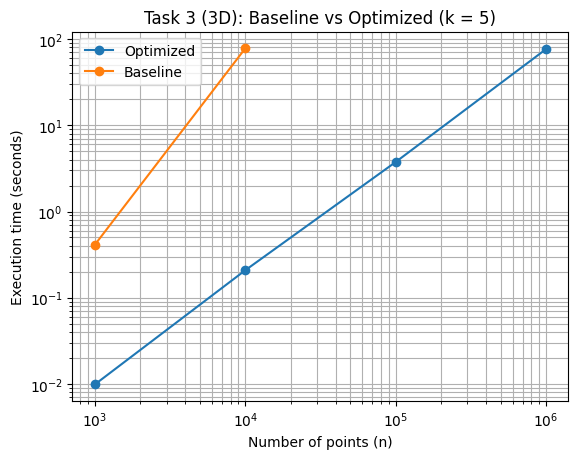

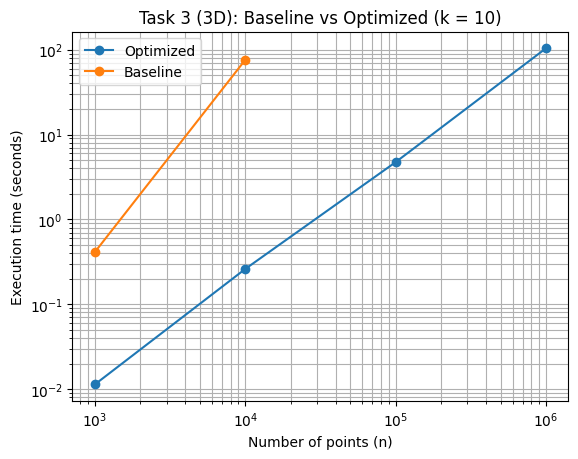

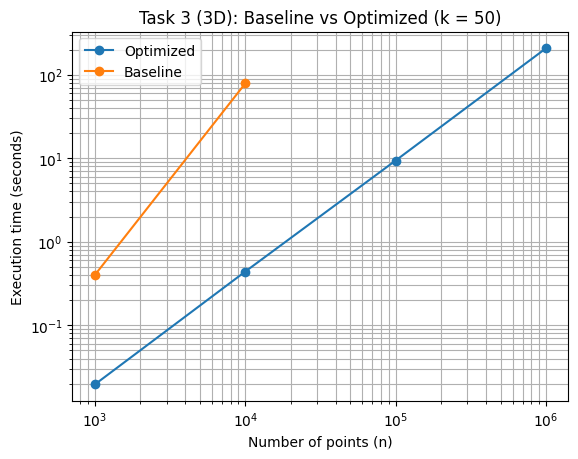

In [23]:
for k in sorted(df3["k"].unique()):
    df_k = df3[df3["k"] == k]
    plot_baseline_vs_opt(
        df_k,
        f"Task 3 (3D): Baseline vs Optimized (k = {k})"
    )

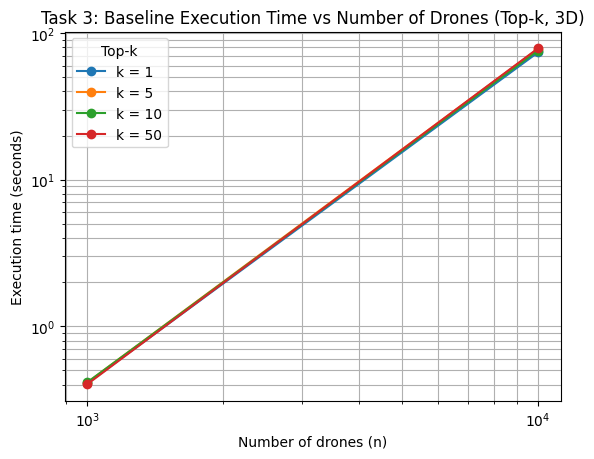

In [27]:
plt.figure()

for k in sorted(df3["k"].unique()):
    df_k = df3[
        (df3["k"] == k) & (df3["baseline_s"].notna())
    ].sort_values("n")

    if len(df_k) == 0:
        continue

    plt.loglog(
        df_k["n"],
        df_k["baseline_s"],
        marker="o",
        label=f"k = {k}"
    )

plt.xlabel("Number of drones (n)")
plt.ylabel("Execution time (seconds)")
plt.title("Task 3: Baseline Execution Time vs Number of Drones (Top-k, 3D)")
plt.legend(title="Top-k")
plt.grid(True, which="both")
plt.show()


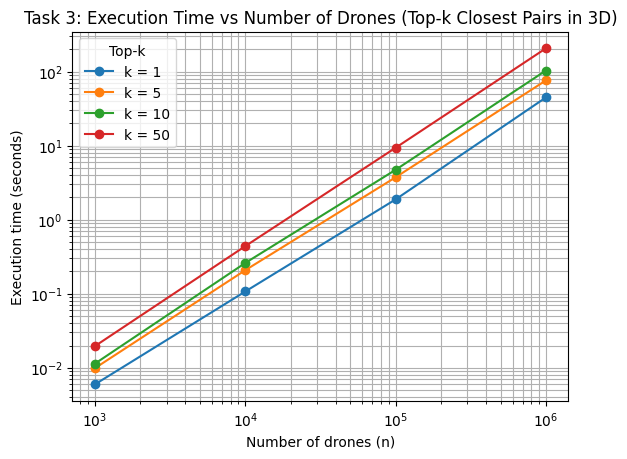

In [26]:
plt.figure()

for k in sorted(df3["k"].unique()):
    df_k = df3[df3["k"] == k].sort_values("n")
    plt.loglog(
        df_k["n"],
        df_k["optimized_s"],
        marker="o",
        label=f"k = {k}"
    )

plt.xlabel("Number of drones (n)")
plt.ylabel("Execution time (seconds)")
plt.title("Task 3: Execution Time vs Number of Drones (Top-k Closest Pairs in 3D)")
plt.legend(title="Top-k")
plt.grid(True, which="both")
plt.show()


## 10. task 4 - dynamic top-k while drones move

state: positions, a 3D hash grid, and the top-k heap.

each tick:
1. move m drones and update their grid cells
2. drop heap pairs that involve a moved drone
3. for each moved drone check nearby cells and push new candidate pairs

this is a heuristic. with a fixed cell size and fixed neighbourhood it can miss pairs if the true top-k distances are bigger than a cell. making the radius adapt to the current threshold would fix that.

In [32]:
Point3D = Tuple[int, float, float, float]

def cell3(p: Point3D, cell: float) -> Tuple[int,int,int]:
    return (int(p[1] // cell), int(p[2] // cell), int(p[3] // cell))

def neighbors_27(c: Tuple[int,int,int]) -> Iterable[Tuple[int,int,int]]:
    cx, cy, cz = c
    for dx in (-1,0,1):
        for dy in (-1,0,1):
            for dz in (-1,0,1):
                yield (cx+dx, cy+dy, cz+dz)

def heap_item_topk(d2: float, a: int, b: int) -> Tuple[float,int,int]:
    pair = ordered_pair(a,b)
    return (-d2, -pair[0], -pair[1])

class DynamicTopK3D:
    def __init__(self, points: List[Point3D], k: int, cell_size: float = 100.0):
        self.k = k
        self.cell_size = cell_size
        self.pos: Dict[int, Point3D] = {p[0]: p for p in points}
        self.grid: Dict[Tuple[int,int,int], set[int]] = {}
        for p in points:
            self.grid.setdefault(cell3(p, self.cell_size), set()).add(p[0])

        self.heap: List[Tuple[float,int,int]] = []
        self.in_heap: set[Tuple[int,int]] = set()
        self._build_initial_heap()

    def _push_pair(self, d2: float, a: int, b: int) -> None:
        pair = ordered_pair(a,b)
        if pair in self.in_heap:
            return
        item = heap_item_topk(d2, a, b)

        if len(self.heap) < self.k:
            heapq.heappush(self.heap, item)
            self.in_heap.add(pair)
        else:
            if item > self.heap[0]:
                # remove old worst
                worst = heapq.heapreplace(self.heap, item)
                worst_pair = (-worst[1], -worst[2])
                self.in_heap.discard(worst_pair)
                self.in_heap.add(pair)

    def _current_thr(self) -> float:
        return float("inf") if len(self.heap) < self.k else -self.heap[0][0]

    def _build_initial_heap(self) -> None:
        # Candidate generation using local neighborhoods (27 cells)
        for a_id, a in self.pos.items():
            ca = cell3(a, self.cell_size)
            for nc in neighbors_27(ca):
                for b_id in self.grid.get(nc, set()):
                    if b_id <= a_id:
                        continue
                    d2 = dist2_3d(a, self.pos[b_id])
                    if d2 <= self._current_thr():
                        self._push_pair(d2, a_id, b_id)

    def update_positions(self, updates: List[Tuple[int, float, float, float]]) -> None:
        moved = set()

        # Step 1: apply updates + grid relocation
        for drone_id, x, y, z in updates:
            if drone_id not in self.pos:
                continue
            old = self.pos[drone_id]
            old_c = cell3(old, self.cell_size)
            new_p: Point3D = (drone_id, x, y, z)
            new_c = cell3(new_p, self.cell_size)
            self.pos[drone_id] = new_p
            moved.add(drone_id)

            if old_c != new_c:
                self.grid.get(old_c, set()).discard(drone_id)
                self.grid.setdefault(new_c, set()).add(drone_id)

        if not moved:
            return

        # Step 2: remove affected pairs from heap
        kept = []
        self.in_heap.clear()
        for item in self.heap:
            pair = (-item[1], -item[2])
            if pair[0] not in moved and pair[1] not in moved:
                kept.append(item)
                self.in_heap.add(pair)
        heapq.heapify(kept)
        self.heap = kept

        # Step 3: add new candidate pairs involving moved drones (local neighborhoods)
        for a_id in moved:
            a = self.pos[a_id]
            ca = cell3(a, self.cell_size)
            for nc in neighbors_27(ca):
                for b_id in self.grid.get(nc, set()):
                    if b_id == a_id:
                        continue
                    d2 = dist2_3d(a, self.pos[b_id])
                    if d2 <= self._current_thr():
                        self._push_pair(d2, a_id, b_id)

    def topk(self) -> List[Tuple[float, Tuple[int,int]]]:
        res = [(-d2, (-id1, -id2)) for (d2, id1, id2) in self.heap]
        res.sort(key=lambda x: (x[0], x[1][0], x[1][1]))
        return res

def simulate_task4(n: int = 10_000, k: int = 10, m_moves: int = 100, steps: int = 5) -> pd.DataFrame:
    # generate points in-memory
    points: List[Point3D] = [(i,
                             random.uniform(0.0, MAP_SIZE),
                             random.uniform(0.0, MAP_SIZE),
                             random.uniform(0.0, MAP_SIZE)) for i in range(n)]

    t0 = time.time()
    tracker = DynamicTopK3D(points, k=k, cell_size=100.0)
    t_init = time.time() - t0

    rows = [{"step": 0, "update_s": 0.0, "first_d": math.sqrt(tracker.topk()[0][0])}]

    for s in range(1, steps + 1):
        moved_ids = random.sample(range(n), m_moves)
        updates = [(i,
                    random.uniform(0.0, MAP_SIZE),
                    random.uniform(0.0, MAP_SIZE),
                    random.uniform(0.0, MAP_SIZE)) for i in moved_ids]

        t1 = time.time()
        tracker.update_positions(updates)
        t_upd = time.time() - t1

        rows.append({"step": s, "update_s": t_upd, "first_d": math.sqrt(tracker.topk()[0][0])})

    df = pd.DataFrame(rows)
    df.attrs["init_time_s"] = t_init
    return df


df4 = simulate_task4(n=10_000, k=10, m_moves=100, steps=5)
print("Initialization time (s):", df4.attrs["init_time_s"])
display(df4)

Initialization time (s): 0.0552670955657959


,step,update_s,first_d
0,0,0.000000,4.303721
1,1,0.000566,4.303721
2,2,0.000564,4.303721
3,3,0.000555,4.303721
4,4,0.000545,4.303721
5,5,0.000608,4.303721


## 11. task 4 update time per step

the point is that the update cost depends on m (drones moved), not on recomputing everything.

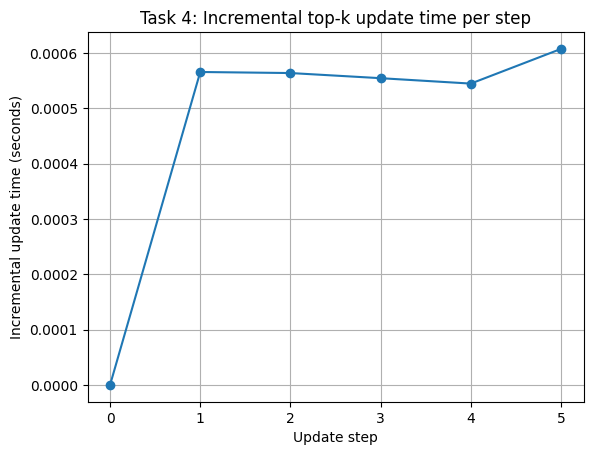

In [33]:
def plot_task4_updates(df: pd.DataFrame) -> None:
    plt.figure()
    plt.plot(df["step"], df["update_s"], marker="o")
    plt.xlabel("Update step")
    plt.ylabel("Incremental update time (seconds)")
    plt.title("Task 4: Incremental top-k update time per step")
    plt.grid(True)
    plt.show()

plot_task4_updates(df4)


### task 4 complexity

n = drones, m = moved per step, k = pairs tracked, ρ = drones in the neighbourhood checked per moved drone

per step: O(k) to clean the heap + O(m · ρ · log k) for new candidates → **O(k + m · ρ · log k)**

worst case (everything clustered, everything moves) ρ = m = Θ(n) so it's Θ(n² log k), no better than recomputing. but with normal spread ρ stays small and it's around O(m log k), which is what the plot shows.